# Tema 20 bis · Aprender actuando: refuerzo e imitación

Un agente que aprende con recompensas, y otro que aprende imitando a un experto.

Este cuaderno es el tema 20 bis de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/20-bis-aprender-actuando-refuerzo-e-imitacion/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

# Teoría

**Tema optativo.** Este tema es para quien quiera ir más allá. La ruta sigue en el tema 21 sin él: ningún tema posterior lo necesita. Si lo haces, te deja una idea nueva de cómo puede aprender una máquina y repasa de paso lo que viste de PyTorch y de redes convolucionales.

## La pregunta

¿Cómo aprendiste a andar en bicicleta? Nadie te dio una tabla con miles de ejemplos de «en esta posición, gira el manubrio 5 grados». Probaste, te caíste, volviste a probar, y poco a poco tu cuerpo aprendió qué movimientos te mantenían arriba. Caerte era una mala señal; avanzar sin caerte, una buena. Nadie te dijo la respuesta correcta en cada instante: solo sabías, al final, si te había ido bien o mal.

Hasta ahora, todos los modelos de la ruta aprendieron de **ejemplos con su respuesta**: esta foto es una zapatilla, esta casa vale tanto. Eso es el aprendizaje **supervisado**. Este tema trata de otras dos maneras de aprender, las dos pensadas para un **agente** que tiene que **actuar**: moverse, elegir, decidir paso a paso.

- **Aprendizaje por refuerzo** (*reinforcement learning*). El agente prueba acciones y recibe **recompensas**: un premio cuando le va bien, un castigo cuando le va mal. Nadie le dice qué hacer; tiene que descubrirlo. Así se entrenan programas que juegan, robots que aprenden a caminar y parte de los modelos de lenguaje que conversan (lo verás de nombre en el tema 24).
- **Aprendizaje por imitación** (*imitation learning*). El agente mira a un **experto** hacerlo bien y aprende a copiarlo. Si el experto deja un registro de qué hizo en cada situación, imitarlo vuelve a ser clasificación supervisada, con todo lo que ya sabes.

Vamos a trabajar con un robot en una cuadrícula de 8 × 8 casillas, con paredes, trampas y una meta. En este tema vas a:

- describir un problema como **agente**, **estados**, **acciones**, **recompensa** y **episodio**, y explicar el **factor de descuento** γ;
- programar en NumPy la **iteración de valor** y el **Q-learning** con ε-greedy, y leer la política que aprenden como un mapa de flechas;
- explicar el dilema entre **explorar** y **explotar**, y el efecto de α, γ y ε;
- enseñar a un robot **imitando** a un experto, con una red convolucional que mira el mapa como un tensor de 3 × 8 × 8, y medir cuántas veces llega a la meta en mapas que nunca vio;
- reconocer por qué los errores de la imitación **se acumulan** y en qué consiste la idea de **DAgger**.

Necesitas lo de los temas 3 (arreglos de NumPy), 5 (probabilidad y promedio), 8 (softmax y entropía cruzada), 18 (PyTorch y la función `entrenar`) y 20 (convoluciones).

## Actividad: el robot que aprende

El robot (la bola coral) empieza en la esquina de arriba y quiere llegar a la meta, abajo a la derecha. No conoce el mapa: solo puede probar. Cada vez que llega a la meta recibe +1; si cae en una trampa (las casillas con ×), recibe −1. Una partida de principio a fin se llama **episodio**. Después de cada paso, el robot anota en cada casilla qué tan buena le pareció cada una de las cuatro direcciones; el color de la casilla muestra el mejor de esos cuatro números y la flecha, la dirección que hoy le parece mejor.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/20-bis-aprender-actuando-refuerzo-e-imitacion/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Pulsa «Un episodio» varias veces. Al principio el robot deambula al azar. ¿Cuántos episodios tarda en llegar a la meta por primera vez? Cuando llega, ¿en qué casillas aparecen las primeras flechas?
2. Pulsa «100 episodios» dos o tres veces. Sigue las flechas desde el inicio: ¿llevan a la meta por el camino más corto?
3. Mira la cifra «recompensa media». ¿Por qué no llega a 1 aunque el robot ya sabe el camino? Pista: mira el deslizador ε.
4. Pulsa «Olvidar lo aprendido», pon ε en 0 y repite. ¿Aprende igual? ¿Hay casillas lejos del camino donde nunca aparece una flecha?
5. Ahora mueve la meta a otra casilla sin olvidar lo aprendido y lanza episodios. ¿Qué hace el robot al principio? ¿Cuántos episodios necesita para corregirse?
6. Cambia γ a 0,5 y después a 0,99. ¿Qué les pasa a los colores lejos de la meta?

Lo que hace el robot de la actividad se llama **Q-learning**, y al final de la sección «Q-learning: aprender probando» vas a poder programarlo en unas 25 líneas.

## Agente, entorno y recompensa

Todo problema de refuerzo tiene las mismas piezas. Las nombramos con el robot de la actividad:

- El **agente** es quien decide: el robot.
- El **entorno** es el mundo donde actúa: la cuadrícula con sus paredes, trampas y meta.
- Un **estado** es la situación en un momento dado. Aquí basta con la casilla donde está el robot, una pareja (fila, columna).
- Una **acción** es lo que el agente puede hacer en cada paso: moverse arriba, a la derecha, abajo o a la izquierda.
- La **recompensa** es un número que el entorno le da después de cada acción: +1 al entrar en la meta, −1 al caer en una trampa y 0 en cualquier otro paso.
- Un **episodio** es una partida completa: empieza en el inicio y termina en la meta, en una trampa o al llegar a un límite de pasos.
- Una **política** es la regla del agente para elegir: «en esta casilla, voy a la derecha». Es lo que queremos aprender.

El ciclo se repite siempre igual: el agente mira el estado, elige una acción, el entorno le devuelve el estado nuevo y una recompensa, y vuelta a empezar. La diferencia con el aprendizaje supervisado es que nadie le dice cuál era la acción correcta: solo recibe la recompensa, y muchas veces tarde. En la cuadrícula, el robot recibe 0 en todos los pasos menos el último, y tiene que adivinar cuáles de sus pasos anteriores lo llevaron a ese +1.

### La cuadrícula en NumPy

No hace falta ninguna librería especial: el entorno entero son unas pocas líneas. Guardamos el mapa como un arreglo de NumPy de 8 × 8 letras y escribimos una función `paso` que mueve al robot y devuelve lo que pasó.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# La cuadrícula: «I» inicio, «M» meta, «T» trampa, «#» pared, «.» libre
MAPA = np.array([list(fila) for fila in [
    "I..#....",
    ".#.#.##.",
    ".#...#..",
    ".##T.#.#",
    "....##..",
    ".#T.....",
    ".#.##T#.",
    "...#..TM",
]])
# Arriba, derecha, abajo, izquierda: cuánto cambian la fila y la columna
MOVIMIENTOS = [(-1, 0), (0, 1), (1, 0), (0, -1)]
FLECHAS = ["↑", "→", "↓", "←"]


def paso(mapa, estado, accion):
    """Mueve al robot; devuelve (nuevo estado, recompensa, terminado)."""
    fila, col = estado
    df, dc = MOVIMIENTOS[accion]
    nf, nc = fila + df, col + dc
    # 0 <= nf < 8 se lee «nf está entre 0 y 7». Contra una pared
    # o el borde, el robot se queda donde estaba.
    if not (0 <= nf < 8 and 0 <= nc < 8) or mapa[nf, nc] == "#":
        nf, nc = fila, col
    if mapa[nf, nc] == "M":
        return (nf, nc), 1.0, True
    if mapa[nf, nc] == "T":
        return (nf, nc), -1.0, True
    return (nf, nc), 0.0, False


print(MAPA.shape)
# Tres pasos desde el inicio: arriba (choca con el borde), abajo, derecha
estado = (0, 0)
for accion in [0, 2, 1]:
    estado, recompensa, fin = paso(MAPA, estado, accion)
    print(FLECHAS[accion], estado, recompensa, fin)

(8, 8)
↑ (0, 0) 0.0 False
↓ (1, 0) 0.0 False
→ (1, 0) 0.0 False


El primer paso choca con el borde y el robot no se mueve; el tercero choca con la pared de la casilla (1, 1). Las acciones son números del 0 al 3, y `FLECHAS[accion]` solo sirve para leerlas.

Este entorno es **determinista**: la misma acción en la misma casilla da siempre el mismo resultado. Muchos entornos reales no lo son (un robot que resbala, un dado en un juego), y los métodos de este tema funcionan también ahí, aunque necesitan más episodios.

¿Qué tan difícil es llegar a la meta sin saber nada? Probemos con un robot que elige cada acción al azar, mil episodios de hasta 100 pasos:

In [ ]:
rng = np.random.default_rng(0)
resultados = {"meta": 0, "trampa": 0, "se acabaron los pasos": 0}
for episodio in range(1000):
    estado = (0, 0)
    for t in range(100):
        estado, recompensa, fin = paso(MAPA, estado, rng.integers(4))
        if fin:
            break
    if recompensa > 0:
        resultados["meta"] += 1
    elif recompensa < 0:
        resultados["trampa"] += 1
    else:
        resultados["se acabaron los pasos"] += 1
print(resultados)

{'meta': 6, 'trampa': 670, 'se acabaron los pasos': 324}


De 1000 episodios, el robot al azar llegó a la meta solo 6 veces; en 670 cayó en una trampa. (`rng.integers(4)` da un entero al azar entre 0 y 3, y `elif` es «si no, y si…».) Aprender, aquí, es pasar de 6 en 1000 a casi siempre.

### El factor de descuento γ

¿Cómo comparamos dos maneras de jugar? Sumando las recompensas que recibe el agente desde ahora hasta el final del episodio. Pero no todas valen lo mismo: un premio que llega pronto vale más que uno que llega dentro de mucho, igual que un boliviano hoy vale más que un boliviano dentro de diez años. Por eso cada recompensa futura se multiplica por un **factor de descuento** γ (la letra griega gamma), un número entre 0 y 1, una vez por cada paso de espera. La suma descontada se llama **retorno** *G*:

$$G = {r}_{1} + \gamma {r}_{2} + {\gamma}^{2} {r}_{3} + {\gamma}^{3} {r}_{4} + \cdots$$

- *r*₁ es la recompensa del primer paso, *r*₂ la del segundo, y así.
- Con γ = 0,9, el premio del segundo paso vale el 90 %, el del tercero el 81 %, el del cuarto el 72,9 %.

En nuestra cuadrícula solo el último paso tiene recompensa, así que si el robot llega a la meta en *k* pasos, su retorno es γ elevado a *k* − 1:

In [ ]:
gamma = 0.9
for pasos in [1, 2, 5, 14, 30]:
    print(f"Meta en {pasos:2d} pasos: retorno {gamma ** (pasos - 1):.3f}")

Meta en  1 pasos: retorno 1.000
Meta en  2 pasos: retorno 0.900
Meta en  5 pasos: retorno 0.656
Meta en 14 pasos: retorno 0.254
Meta en 30 pasos: retorno 0.047


El descuento hace que el agente tenga **prisa**: entre dos caminos que llegan a la meta, el más corto da más retorno. Con γ cerca de 0, el agente solo se fija en lo inmediato; con γ cerca de 1, planifica a largo plazo. (En el `f"{pasos:2d}"`, el `2d` pide un entero ocupando dos lugares, para que las columnas queden alineadas.)

## Iteración de valor: cuando conocemos el mapa

Empecemos por el caso fácil: supongamos que **conocemos** el mapa y la función `paso`. Entonces podemos calcular, para cada casilla, el mejor retorno posible desde ahí. Ese número se llama el **valor** de la casilla, *V*(*s*).

La intuición: el valor de una casilla es lo que gano con el mejor paso que puedo dar desde ella, más el valor (descontado) de la casilla adonde llego. Las casillas de al lado de la meta valen 1; las de al lado de esas, 0,9; las siguientes, 0,81; y así se va «derramando» el valor desde la meta hacia atrás. En fórmula, esta es la **ecuación de Bellman**:

$$V ( s ) = \max_{a} [ r ( s , a ) + \gamma \cdot V ( {s}^{'} ) ]$$

- *s* es la casilla, *a* una de las cuatro acciones y *s*′ (se lee «ese prima») la casilla adonde lleva esa acción.
- *r*(*s*, *a*) es la recompensa de ese paso: 1, −1 o 0.
- «máx» sobre *a* significa probar las cuatro acciones y quedarse con la mejor.
- Si el paso termina el episodio (meta o trampa), no hay futuro: el término γ · *V*(*s*′) no se suma.

La **iteración de valor** usa la ecuación como receta: empieza con *V* = 0 en todas las casillas y aplica la fórmula a todas, una y otra vez, hasta que los números dejan de cambiar. En cada vuelta el valor avanza una casilla más lejos de la meta.

In [ ]:
def valores_q(mapa, V, estado, gamma):
    """Lo que vale cada una de las 4 acciones desde `estado`, según V."""
    q = np.zeros(4)
    for a in range(4):
        siguiente, r, fin = paso(mapa, estado, a)
        q[a] = r if fin else r + gamma * V[siguiente]
    return q


def iteracion_de_valor(mapa, gamma=0.9, tolerancia=1e-6):
    V = np.zeros((8, 8))
    for vuelta in range(1, 1001):
        V_nuevo = np.zeros((8, 8))
        for f in range(8):
            for c in range(8):
                # Paredes, meta y trampas no tienen futuro: valor 0
                if mapa[f, c] in "#MT":
                    continue
                V_nuevo[f, c] = valores_q(mapa, V, (f, c), gamma).max()
        cambio = np.abs(V_nuevo - V).max()
        V = V_nuevo
        if cambio < tolerancia:
            break
    return V, vuelta


V, vueltas = iteracion_de_valor(MAPA)
print(f"Se estabilizó en {vueltas} vueltas")
print(f"Valor del inicio: {V[0, 0]:.3f}")
print(np.round(V, 2))

Se estabilizó en 18 vueltas
Valor del inicio: 0.254
[[0.25 0.23 0.21 0.   0.31 0.35 0.39 0.43]
 [0.28 0.   0.19 0.   0.28 0.   0.   0.48]
 [0.31 0.   0.21 0.23 0.25 0.   0.59 0.53]
 [0.35 0.   0.   0.   0.23 0.   0.66 0.  ]
 [0.39 0.43 0.48 0.53 0.   0.   0.73 0.81]
 [0.35 0.   0.   0.59 0.66 0.73 0.81 0.9 ]
 [0.31 0.   0.21 0.   0.   0.   0.   1.  ]
 [0.28 0.25 0.23 0.   0.   0.   0.   0.  ]]


El valor del inicio es 0,254, el mismo retorno que calculamos para una meta en 14 pasos: el camino más corto desde el inicio tiene 14 pasos. (`r if fin else ...` es un `if` en una sola línea: vale `r` si `fin` es verdadero y lo de después del `else` si no. La línea `if mapa[f, c] in "#MT"` pregunta si la letra está entre esas tres.)

Con *V* calculado, la mejor **política** sale sola: en cada casilla, elegir la acción con el valor más alto.

In [ ]:
def politica_desde_v(mapa, V, gamma=0.9):
    politica = np.zeros((8, 8), dtype=int)
    for f in range(8):
        for c in range(8):
            politica[f, c] = valores_q(mapa, V, (f, c), gamma).argmax()
    return politica


def mostrar(mapa, politica):
    """Imprime la política como flechas, con paredes, meta y trampas."""
    for f in range(8):
        fila = [mapa[f, c] if mapa[f, c] in "#MT"
                else FLECHAS[politica[f, c]] for c in range(8)]
        print(" ".join(fila))


politica_optima = politica_desde_v(MAPA, V)
mostrar(MAPA, politica_optima)

↓ ← ← # → → → ↓
↓ # ↑ # ↑ # # ↓
↓ # → → ↑ # ↓ ←
↓ # # T ↑ # ↓ #
→ → → ↓ # # → ↓
↑ # T → → → → ↓
↑ # ↓ # # T # ↓
↑ ← ← # ↑ ↓ T M


Sigue las flechas desde la esquina de arriba: el robot baja por la columna izquierda, cruza por el medio esquivando las trampas y llega a la meta. Desde las casillas de arriba a la derecha, en cambio, las flechas van por el otro lado, por la columna derecha: cada casilla tiene su propio mejor camino. El dibujo lo muestra mejor:

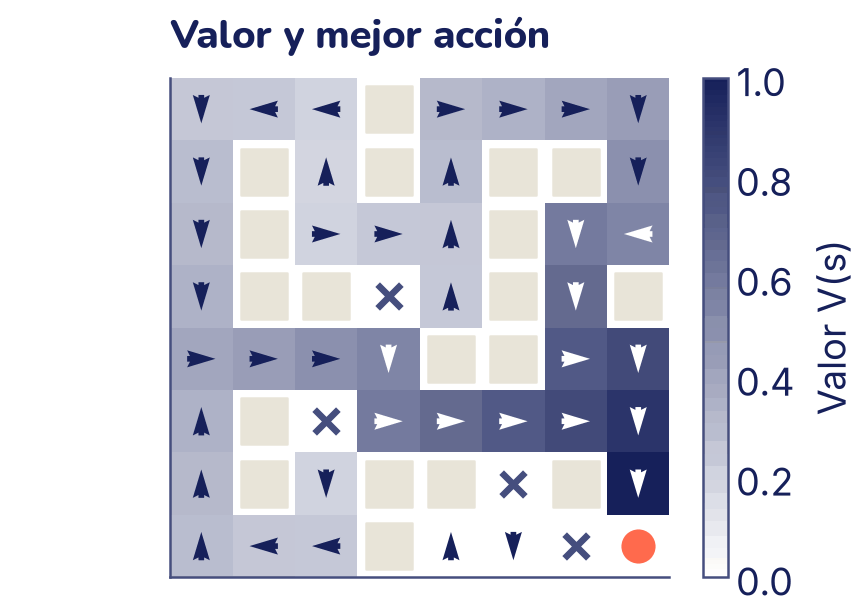

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

blanco_tinta = LinearSegmentedColormap.from_list("bt", ["white", "C0"])
# Paredes, meta y trampas sin color de valor: las pintamos aparte.
# np.isin dice, casilla por casilla, si la letra está en la lista.
valor = np.ma.masked_where(np.isin(MAPA, ["#", "M", "T"]), V)
plt.imshow(valor, cmap=blanco_tinta, vmin=0, vmax=1)
plt.colorbar(label="Valor V(s)")
filas, cols = np.indices((8, 8))
libres = ~np.isin(MAPA, ["#", "M", "T"])
# .flat recorre el arreglo casilla por casilla, fila tras fila
dx = np.array([MOVIMIENTOS[a][1] for a in politica_optima.flat])
dy = np.array([MOVIMIENTOS[a][0] for a in politica_optima.flat])
# Flechas blancas sobre el fondo oscuro y de tinta sobre el claro
colores = np.where(V.flat > 0.5, "white", "C0")[libres.flat]
plt.quiver(cols[libres], filas[libres], dx[libres.flat], dy[libres.flat],
           color=colores, angles="xy", scale_units="xy", scale=2.2,
           pivot="middle", width=0.012)
# Solo para dibujar: paredes, trampas y meta
paredes = np.argwhere(MAPA == "#")
plt.scatter(paredes[:, 1], paredes[:, 0], marker="s", s=330, color="C3")
trampas = np.argwhere(MAPA == "T")
plt.scatter(trampas[:, 1], trampas[:, 0], marker="x", s=90, color="C2")
plt.scatter([7], [7], s=160, color="C1")
plt.xticks([])
plt.yticks([])
plt.title("Valor y mejor acción")
plt.show()

Las dos casillas blancas de abajo, entre la pared y las trampas, están encerradas: desde ahí no se puede llegar a la meta, su valor es 0 y sus flechas no significan nada. Un detalle sobre `np.ma.masked_where`: arma un arreglo «enmascarado», en el que las casillas marcadas no se pintan (`imshow` las deja en blanco). Y `np.indices((8, 8))` da dos arreglos con el número de fila y de columna de cada casilla.

La iteración de valor es exacta y rápida, pero tiene una condición fuerte: **hay que conocer el mapa**, es decir, poder llamar a `paso` desde cualquier casilla para ver qué pasaría. Un robot de verdad no puede preguntarle al mundo «¿qué pasa si me muevo a la izquierda desde allá?» sin ir hasta allá y moverse.

## Q-learning: aprender probando

El **Q-learning** no necesita conocer el mapa. El robot juega episodios y va llenando una tabla *Q* con un número para cada casilla y cada acción: *Q*(*s*, *a*) es su estimación de lo que gana si hace *a* en *s* y después sigue jugando bien. Son 8 × 8 × 4 = 256 números, todos en 0 al empezar. Fue lo que viste en la actividad: el color de cada casilla era el máximo de sus cuatro *Q* y la flecha, la acción de ese máximo.

Después de cada paso, el robot corrige el número de la acción que acaba de probar. La idea: «creía que esta acción valía *Q*(*s*, *a*); acabo de ver que da *r* y me deja en *s*′, desde donde lo mejor que conozco vale máx *Q*(*s*′, ·). Entonces la acción valía más bien *r* + γ · máx *Q*(*s*′, ·). Me acerco un poco a ese número».

$$Q ( s , a ) \leftarrow Q ( s , a ) + \alpha \cdot [ r + \gamma \cdot \max_{{a}^{'}} Q ( {s}^{'} , {a}^{'} ) - Q ( s , a ) ]$$

- La flecha ← significa «reemplazar por»: el nuevo *Q*(*s*, *a*) es lo que está a la derecha.
- Lo que va entre corchetes es la **sorpresa**: cuánto se equivocaba la estimación. Si es positiva, la acción era mejor de lo que creía.
- α (alfa) es la **tasa de aprendizaje**, entre 0 y 1: qué parte de la sorpresa se corrige de una vez. Es la misma idea que la tasa del descenso de gradiente del tema 6.
- Si el paso terminó el episodio, no hay futuro y la sorpresa es solo *r* − *Q*(*s*, *a*).

Es la ecuación de Bellman otra vez, pero usada a pedacitos: en lugar de recorrer todas las casillas con un mapa conocido, corrige solo la casilla donde está el robot, con lo que acaba de vivir.

### Explorar o explotar: ε-greedy

Falta decidir cómo elige el robot sus acciones mientras aprende. Si siempre hace la que hoy le parece mejor (**explotar** lo que sabe), puede quedarse para siempre con el primer camino que encontró, aunque haya otro mejor que nunca probó. Si siempre elige al azar (**explorar**), aprende mucho del mapa pero nunca aprovecha lo aprendido. La regla **ε-greedy** (*greedy* es «codicioso» en inglés; ε es la letra épsilon) mezcla las dos: con probabilidad ε elige una acción al azar y, el resto de las veces, la mejor según *Q*. Si hay empate entre varias mejores, sortea entre ellas: al principio, cuando todo vale 0, el robot camina al azar.

In [ ]:
def q_learning(mapa, episodios=500, alfa=0.5, gamma=0.9, epsilon=0.1,
               semilla=0):
    rng = np.random.default_rng(semilla)
    Q = np.zeros((8, 8, 4))
    recompensas = []
    for episodio in range(episodios):
        s, total = (0, 0), 0.0
        for t in range(100):
            if rng.random() < epsilon:
                a = rng.integers(4)                  # explorar
            else:
                # Explotar: la mejor acción; si empatan, una de ellas
                mejores = np.flatnonzero(Q[s] == Q[s].max())
                a = rng.choice(mejores)
            s2, r, fin = paso(mapa, s, a)
            objetivo = r if fin else r + gamma * Q[s2].max()
            Q[s][a] += alfa * (objetivo - Q[s][a])
            total += r
            s = s2
            if fin:
                break
        recompensas.append(total)
    return Q, np.array(recompensas)


Q, recompensas = q_learning(MAPA)
print(f"Recompensa media, primeros 100 episodios: "
      f"{recompensas[:100].mean():.2f}")
print(f"Recompensa media, últimos 100 episodios: "
      f"{recompensas[-100:].mean():.2f}")
print(f"Q del inicio: {Q[0, 0].max():.3f}  (V del inicio: {V[0, 0]:.3f})")

Recompensa media, primeros 100 episodios: -0.24
Recompensa media, últimos 100 episodios: 0.84
Q del inicio: 0.254  (V del inicio: 0.254)


Unos detalles del código. `Q[s]` con `s = (fila, columna)` da los cuatro números de esa casilla, y `Q[s][a]` uno de ellos. `np.flatnonzero` da las posiciones donde algo es verdadero, y `rng.choice` elige una al azar. La recompensa de un episodio es +1, −1 o 0, así que su promedio dice qué tan seguido llega el robot a la meta.

En los primeros 100 episodios la recompensa media fue −0,24: el robot caía en trampas más seguido de lo que llegaba a la meta. En los últimos 100 subió a 0,84. Y lo más llamativo: sin conocer el mapa, el *Q* del inicio llegó a 0,254, exactamente el valor que la iteración de valor calculó conociéndolo.

Para leer la política aprendida, tomamos en cada casilla la acción con el *Q* más alto y la comparamos con la política óptima de la iteración de valor:

In [ ]:
politica_q = Q.argmax(axis=2)
mostrar(MAPA, politica_q)
libres = ~np.isin(MAPA, ["#", "M", "T"])
iguales = (politica_q == politica_optima)[libres].sum()
print(f"Coincide con la óptima en {iguales} de {libres.sum()} casillas")

↓ ← ↑ # ↑ ↑ ↑ ↑
↓ # ↑ # ↑ # # ↑
↓ # ↑ ↑ ↑ # ↑ ↑
↓ # # T ↑ # ↓ #
→ → → ↓ # # ↓ ←
↑ # T → → → → ↓
↑ # → # # T # ↓
↑ ↑ ↑ # ↑ ↑ T M
Coincide con la óptima en 24 de 40 casillas


Desde el inicio, las flechas siguen el mismo camino de 14 pasos que la política óptima. Pero solo coinciden en 24 de las 40 casillas libres. ¿Dónde falla? Arriba a la derecha casi todo es ↑: son casillas que el robot casi no visitó. Ahí sus cuatro *Q* siguen en 0 y `argmax` devuelve la primera acción, ↑. El Q-learning solo aprende bien **donde estuvo**.

Probemos tres valores de ε, con todo lo demás igual. Para ver la tendencia dibujamos la **media móvil** de la recompensa (el promedio de los últimos 20 episodios, como en el tema 13). Además medimos cuánto del mapa aprendió el robot: desde cada casilla libre, seguimos sus flechas y contamos desde cuántas llega a la meta.

ε = 0.0: recompensa media al final 1.00, llega desde 17 de 40 casillas
ε = 0.1: recompensa media al final 0.84, llega desde 21 de 40 casillas
ε = 0.3: recompensa media al final 0.46, llega desde 26 de 40 casillas


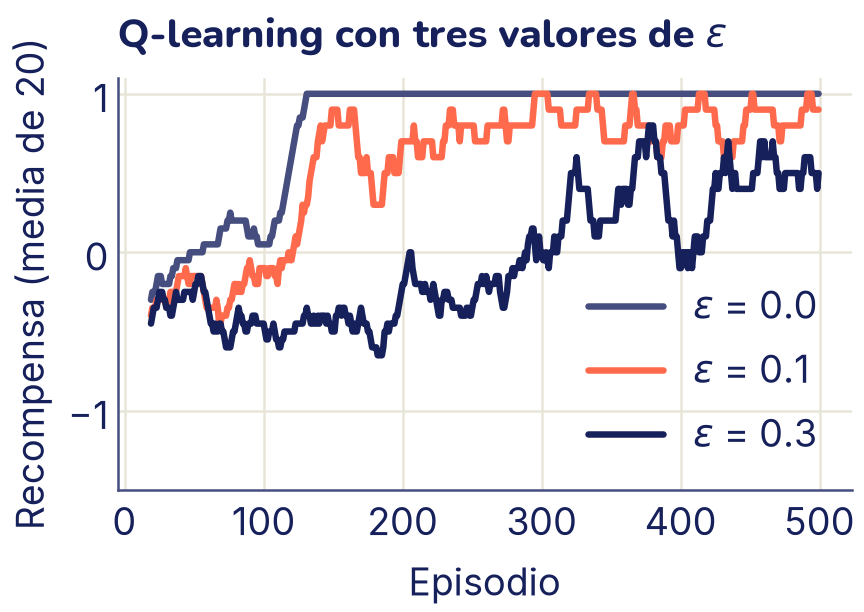

In [ ]:
import pandas as pd


def llega_desde(mapa, Q):
    """Desde cuántas casillas libres llegan a la meta las flechas de Q."""
    llegan = 0
    for f, c in np.argwhere(~np.isin(mapa, ["#", "M", "T"])):
        s = (f, c)
        for t in range(100):
            s, r, fin = paso(mapa, s, Q[s].argmax())
            if fin:
                break
        llegan += r > 0
    return llegan


for epsilon, color in [(0.0, "C2"), (0.1, "C1"), (0.3, "C0")]:
    Q_e, rec = q_learning(MAPA, epsilon=epsilon)
    print(f"ε = {epsilon}: recompensa media al final "
          f"{rec[-100:].mean():.2f}, llega desde "
          f"{llega_desde(MAPA, Q_e)} de 40 casillas")
    plt.plot(pd.Series(rec).rolling(20).mean(), color=color,
             label=rf"$\varepsilon$ = {epsilon}")
plt.xlabel("Episodio")
plt.ylabel("Recompensa (media de 20)")
plt.ylim(-1.5, 1.1)
plt.legend(loc="lower right")
plt.title(r"Q-learning con tres valores de $\varepsilon$")
plt.show()

Las dos cifras cuentan historias opuestas:

- **Mientras aprende**, explorar cuesta. Con ε = 0, el robot encontró un camino y lo repitió sin desviarse: recompensa 1,00. Con ε = 0,3, uno de cada tres pasos es al azar y muchas veces termina en una trampa: 0,46. (Con ε = 0 igual aprendió algo, porque al principio todos los *Q* empatan en 0 y el desempate es al azar.)
- **Lo que aprendió**, en cambio, crece con la exploración: siguiendo sus flechas, el robot con ε = 0 llega a la meta desde 17 casillas; con ε = 0,3, desde 26. Quien nunca se desvía del camino conocido no sabe qué hacer cuando lo ponen en otro lugar.

Ese es el dilema entre **explorar y explotar**, y no es solo de robots: ¿vuelves al restaurante que ya sabes que te gusta o pruebas uno nuevo?

### Los tres botones: α, γ y ε

- **α, la tasa de aprendizaje.** Con α chico, cada experiencia mueve poco la tabla: se aprende lento pero con calma. Con α = 1, cada estimación se reemplaza entera por lo último que se vio; en un entorno determinista como el nuestro eso funciona, pero si el entorno tiene azar, la tabla salta de un lado al otro. En entornos con azar se usan valores como 0,1.
- **γ, el descuento.** Decide qué tan lejos mira el agente. Con γ chico, el valor de la meta casi no llega a las casillas lejanas (lo viste en el paso 6 de la actividad). Con γ = 1, llegar en 14 pasos o en 100 da lo mismo, y el agente pierde la prisa (ejercicio 3).
- **ε, la exploración.** Más ε es más conocimiento del mapa pero peores episodios mientras aprende. Una receta muy usada es empezar con ε grande y achicarlo poco a poco a medida que el robot sabe más.

Una limitación grande: la tabla *Q* tiene una fila por estado. Una cuadrícula de 8 × 8 tiene 64 estados, pero un juego de video tiene tantos estados posibles (todas las imágenes de la pantalla) que no caben en ninguna tabla. Ahí se reemplaza la tabla por una red neuronal que recibe el estado y devuelve los cuatro valores *Q*: eso se llama **Q-learning profundo** (*deep Q-learning*), y con esa idea un programa aprendió en 2015 a jugar decenas de juegos de Atari mirando solo la pantalla.

## Aprender imitando: clonación de comportamiento

El Q-learning necesitó cientos de episodios para un solo mapa, y si movemos la meta, tiene que volver a aprender (el paso 5 de la actividad). ¿Y si en lugar de probar, el robot mirara a alguien que ya sabe hacerlo?

Esa es la **clonación de comportamiento** (*behavior cloning*): un **experto** juega, guardamos cada situación que vio y la acción que eligió, y entrenamos un clasificador que, dada la situación, prediga la acción del experto. Es aprendizaje supervisado puro, como en el tema 18: las «fotos» son mapas y las «clases» son las cuatro acciones. Así aprendieron sus primeros pasos varios autos autónomos: imitando a conductores humanos.

Vamos a enseñarle al robot a llegar a la meta en **cualquier** mapa, no en uno solo. Cada mapa nuevo tendrá paredes al azar y la meta en otro lugar.

### El experto: el camino más corto

Nuestro experto no es una persona, sino un programa que conoce el mapa entero y siempre toma el camino más corto. Lo calcula con una **búsqueda en anchura** (*breadth-first search*, BFS): parte de la meta y marca con 1 sus casillas vecinas, con 2 las vecinas de esas, y así, como una mancha de agua que se expande un paso por vez. Al terminar, cada casilla sabe cuántos pasos le faltan para llegar. Para ir por el camino más corto, basta moverse siempre a una vecina con un número menos.

In [ ]:
from collections import deque


def distancias_bfs(mapa, meta):
    """Pasos que faltan hasta la meta desde cada casilla (−1: no llega)."""
    dist = np.full((8, 8), -1)
    dist[meta] = 0
    # Una cola: se agrega por la derecha y se saca por la izquierda
    cola = deque([meta])
    while cola:
        f, c = cola.popleft()
        for df, dc in MOVIMIENTOS:
            nf, nc = f + df, c + dc
            if (0 <= nf < 8 and 0 <= nc < 8 and mapa[nf, nc] != "#"
                    and dist[nf, nc] < 0):
                dist[nf, nc] = dist[f, c] + 1
                cola.append((nf, nc))
    return dist


def experto(dist, estado):
    """La acción que se mueve a una casilla un paso más cerca."""
    f, c = estado
    for a, (df, dc) in enumerate(MOVIMIENTOS):
        nf, nc = f + df, c + dc
        if 0 <= nf < 8 and 0 <= nc < 8 and dist[nf, nc] == dist[f, c] - 1:
            return a

Una **cola** (`deque`, de *double-ended queue*) es una lista pensada para sacar elementos por un lado y agregarlos por el otro: la casilla que entró primero sale primero, y por eso la mancha avanza pareja, de un paso en un paso. El `while cola:` repite mientras la cola no esté vacía.

Ahora los mapas al azar. Cada uno tiene un 25 % de paredes, una meta y un inicio a cuatro pasos o más; si la meta no se puede alcanzar desde el inicio, se sortea otro mapa.

In [ ]:
def mapa_al_azar(rng, prob_pared=0.25):
    """Un mapa con paredes al azar, su inicio y sus distancias."""
    while True:
        mapa = np.where(rng.random((8, 8)) < prob_pared, "#", ".")
        libres = np.argwhere(mapa == ".")
        elegidas = rng.choice(len(libres), 2, replace=False)
        inicio, meta = [tuple(int(v) for v in libres[k]) for k in elegidas]
        mapa[meta] = "M"
        dist = distancias_bfs(mapa, meta)
        if dist[inicio] >= 4:
            return mapa, inicio, dist


rng = np.random.default_rng(1)
mapa, inicio, dist = mapa_al_azar(rng)
for fila in mapa:
    print(" ".join(fila))
print(f"Inicio {inicio}, a {dist[inicio]} pasos de la meta")

. . # . . . . .
. # . . . . . .
# . # . . . . .
. . . . # . . #
. . . . # . . #
. . . . . . . .
# . . M # . # #
. . . . . # . .
Inicio (3, 0), a 6 pasos de la meta


`np.where(condición, "#", ".")` pone «#» donde la condición es verdadera y «.» donde no. `rng.choice(len(libres), 2, replace=False)` elige dos casillas libres distintas (sin reposición, como sacar dos bolillos de una bolsa sin devolver el primero).

### El mapa como tensor

Una red no lee letras. Codificamos cada situación como un tensor de forma (3, 8, 8): tres «canales», como los tres colores de una foto, cada uno una cuadrícula de ceros y unos. El canal 0 marca las paredes; el canal 1, dónde está el robot; el canal 2, dónde está la meta. Es la forma (C, H, W) que espera una capa `nn.Conv2d` del tema 20.

In [ ]:
def codificar(mapa, estado):
    x = np.zeros((3, 8, 8), dtype=np.float32)
    x[0] = mapa == "#"
    x[1][estado] = 1
    x[2] = mapa == "M"
    return x


def demostraciones(mapas):
    """Cada paso del experto en cada mapa: (situación, acción)."""
    X, Y = [], []
    for mapa, inicio, dist in mapas:
        s = inicio
        while mapa[s] != "M":
            a = experto(dist, s)
            X.append(codificar(mapa, s))
            Y.append(a)
            s, _, _ = paso(mapa, s, a)
    return np.array(X), np.array(Y)


rng = np.random.default_rng(0)
mapas_ent = [mapa_al_azar(rng) for _ in range(2000)]
mapas_val = [mapa_al_azar(rng) for _ in range(400)]
X_ent, y_ent = demostraciones(mapas_ent)
X_val, y_val = demostraciones(mapas_val)
print("Entrenamiento:", X_ent.shape, " Validación:", X_val.shape)
print("Acciones del experto:", np.bincount(y_ent))

Entrenamiento: (14602, 3, 8, 8)  Validación: (2967, 3, 8, 8)
Acciones del experto: [3796 3688 3516 3602]


Los 2000 mapas de entrenamiento dan 14 602 ejemplos, uno por cada paso del experto, y los 400 de validación dan 2967. (`np.bincount` cuenta cuántas veces aparece cada entero: 3796 veces la acción 0, ↑, y así.) Dos decisiones importantes. Primero, la validación sale de **otros mapas**, no de otros pasos de los mismos mapas: los pasos de un mismo camino se parecen mucho, y si se repartieran entre entrenamiento y validación, la red sería evaluada con mapas que ya vio (es la fuga de datos del tema 10). Segundo, las cuatro acciones aparecen más o menos igual de seguido, así que la exactitud es una métrica razonable.

### Una CNN que imita

Usamos la función `entrenar` del tema 18, tal cual. Si no la tienes a mano, cópiala aquí; en el tema 18 se explica línea por línea.

In [ ]:
import torch
from torch import nn


def evaluar(modelo, cargador, funcion_perdida, dispositivo="cpu"):
    """Pérdida media y exactitud de `modelo` sobre `cargador`."""
    modelo.eval()
    suma, aciertos, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in cargador:
            x, y = x.to(dispositivo), y.to(dispositivo)
            salida = modelo(x)
            suma += funcion_perdida(salida, y).item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
    return suma / total, aciertos / total


def entrenar(modelo, cargador_ent, cargador_val, epocas, optimizador,
             funcion_perdida=None, planificador=None, dispositivo="cpu",
             mostrar=True):
    """Entrena `modelo` y devuelve el historial de cada época."""
    if funcion_perdida is None:
        funcion_perdida = nn.CrossEntropyLoss()
    modelo.to(dispositivo)
    historial = {"perdida_ent": [], "exactitud_ent": [],
                 "perdida_val": [], "exactitud_val": []}
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma, aciertos, total = 0.0, 0, 0
        for x, y in cargador_ent:
            x, y = x.to(dispositivo), y.to(dispositivo)
            optimizador.zero_grad()
            salida = modelo(x)
            perdida = funcion_perdida(salida, y)
            perdida.backward()
            optimizador.step()
            suma += perdida.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
        if planificador is not None:
            planificador.step()
        perdida_val, exactitud_val = evaluar(
            modelo, cargador_val, funcion_perdida, dispositivo)
        historial["perdida_ent"].append(suma / total)
        historial["exactitud_ent"].append(aciertos / total)
        historial["perdida_val"].append(perdida_val)
        historial["exactitud_val"].append(exactitud_val)
        if mostrar:
            print(f"Época {epoca}: pérdida {suma / total:.3f}, "
                  f"validación {perdida_val:.3f}, "
                  f"exactitud de validación {exactitud_val:.3f}")
    return historial

La red: dos convoluciones de 3 × 3 con *padding* 1 (que conservan el tamaño 8 × 8, sin pooling, porque el mapa ya es chico) y una capa lineal que da los cuatro puntajes, uno por acción. Como en los temas 18 a 20, `CrossEntropyLoss` aplica la softmax y la entropía cruzada del tema 8.

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
cargador_ent = DataLoader(
    TensorDataset(torch.tensor(X_ent), torch.tensor(y_ent)),
    batch_size=64, shuffle=True,
    generator=torch.Generator().manual_seed(0))
cargador_val = DataLoader(
    TensorDataset(torch.tensor(X_val), torch.tensor(y_val)),
    batch_size=256)

imitador = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),
    nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU(),
    nn.Flatten(),
    nn.Linear(32 * 8 * 8, 4),
)
print("Parámetros:", sum(p.numel() for p in imitador.parameters()))
optimizador = torch.optim.Adam(imitador.parameters(), lr=0.001)
historial = entrenar(imitador, cargador_ent, cargador_val, 10, optimizador,
                     dispositivo=device)

Parámetros: 18340
Época 1: pérdida 1.102, validación 0.916, exactitud de validación 0.648
Época 2: pérdida 0.858, validación 0.789, exactitud de validación 0.700
Época 3: pérdida 0.616, validación 0.485, exactitud de validación 0.825
Época 4: pérdida 0.393, validación 0.378, exactitud de validación 0.852
Época 5: pérdida 0.312, validación 0.333, exactitud de validación 0.873
Época 6: pérdida 0.276, validación 0.314, exactitud de validación 0.873
Época 7: pérdida 0.249, validación 0.298, exactitud de validación 0.884
Época 8: pérdida 0.229, validación 0.303, exactitud de validación 0.878
Época 9: pérdida 0.206, validación 0.281, exactitud de validación 0.897
Época 10: pérdida 0.192, validación 0.275, exactitud de validación 0.893


En 10 épocas, unos segundos en CPU, la red acierta la acción del experto en el 89,3 % de los pasos de validación, en mapas que nunca vio. Adivinando al azar acertaría en el 25 %.

### Mapas públicos y mapas ocultos

La exactitud por paso no es lo que nos importa: queremos saber si el robot **llega a la meta**. Para medirlo, lo soltamos en mapas nuevos y dejamos que juegue solo, siguiendo en cada paso la acción con el puntaje más alto, hasta llegar a la meta o hasta 40 pasos.

Preparamos dos grupos de mapas nuevos, con otra semilla. Los **mapas públicos** son los que usamos mientras desarrollamos: para mirar, comparar y decidir. Los **mapas ocultos** se guardan sin mirar y se usan **una sola vez, al final**, para la cifra que se reporta. Es la misma idea de la validación y la prueba del tema 7: si decidimos mirando los mapas ocultos, su cifra deja de ser honesta.

In [ ]:
def jugar(red, mapa, inicio, limite=40):
    """Deja que la red juegue sola. Devuelve si llegó y su recorrido."""
    red.eval()
    s, camino = inicio, [inicio]
    for t in range(limite):
        x = torch.tensor(codificar(mapa, s)).unsqueeze(0).to(device)
        with torch.no_grad():
            a = red(x).argmax().item()
        s, r, fin = paso(mapa, s, a)
        camino.append(s)
        if fin:
            return True, camino
    return False, camino


rng = np.random.default_rng(2026)
mapas_publicos = [mapa_al_azar(rng) for _ in range(300)]
mapas_ocultos = [mapa_al_azar(rng) for _ in range(300)]

partidas = [jugar(imitador, m, i) for m, i, d in mapas_publicos]
llego = np.array([llega for llega, camino in partidas])
pasos = np.array([len(camino) - 1 for llega, camino in partidas])
distancia = np.array([d[i] for m, i, d in mapas_publicos])
# Sin errores: llega con los mismos pasos que el experto
perfecto = llego & (pasos == distancia)
print(f"Llega a la meta en {llego.mean():.1%} de los mapas públicos")
print(f"Llega sin ningún error en {perfecto.mean():.1%}")

Llega a la meta en 77.3% de los mapas públicos
Llega sin ningún error en 73.0%


El robot llega a la meta en el 77,3 % de los mapas públicos, y en el 73,0 % lo hace sin ningún error, con exactamente los pasos del camino más corto. Miremos cuatro partidas: tres en que llega y la primera en que no. (`np.flatnonzero(~llego)` da las posiciones de los mapas donde **no** llegó: `~` invierte verdadero y falso.)

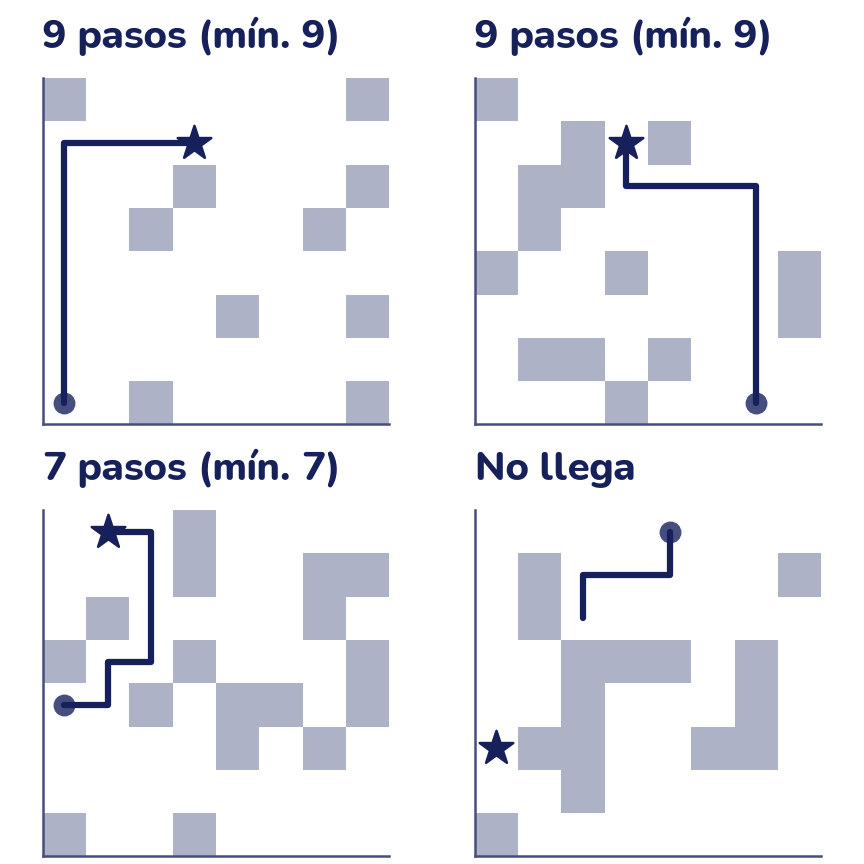

In [ ]:
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
# Tres mapas en que llega y el primero en que no llega
elegidos = [0, 1, 2, np.flatnonzero(~llego)[0]]
for eje, k in zip(ejes.flat, elegidos):
    mapa, inicio, dist = mapas_publicos[k]
    llega, camino = jugar(imitador, mapa, inicio)
    camino = np.array(camino)
    eje.imshow(mapa == "#", cmap=blanco_tinta, vmin=0, vmax=3)
    eje.plot(camino[:, 1], camino[:, 0], color="C0", lw=2.5)
    eje.scatter([inicio[1]], [inicio[0]], s=60, color="C2")
    meta = np.argwhere(mapa == "M")[0]
    eje.scatter([meta[1]], [meta[0]], s=200, color="C0", marker="*")
    eje.set_title(f"{len(camino) - 1} pasos (mín. {dist[inicio]})"
                  if llega else "No llega")
    eje.set_xticks([])
    eje.set_yticks([])
plt.show()

## Por qué los errores de la imitación se acumulan

En la cuarta partida, el robot dio unos pasos y se quedó chocando contra una pared hasta agotar los 40 pasos. Hay algo raro en los números: la red acierta la acción del experto en el 89,3 % de los pasos, pero llega sin errores solo en el 73,0 % de los mapas. ¿Por qué?

Primero, un detalle de medición. A veces hay dos caminos igual de cortos, y el experto elige siempre el primero en el orden arriba, derecha, abajo, izquierda. Si la red elige el otro, cuenta como error, aunque no lo sea. Midamos mejor: en cada paso del experto, ¿la acción de la red también acerca un paso a la meta?

In [ ]:
def proporcion_buena(red, mapas):
    """En los pasos del experto, cuántas veces la red se acerca a la meta."""
    red.eval()
    buenos, total = 0, 0
    for mapa, inicio, dist in mapas:
        s = inicio
        while mapa[s] != "M":
            x = torch.tensor(codificar(mapa, s)).unsqueeze(0).to(device)
            with torch.no_grad():
                a = red(x).argmax().item()
            s_red, _, _ = paso(mapa, s, a)
            buenos += dist[s_red] == dist[s] - 1
            total += 1
            s, _, _ = paso(mapa, s, experto(dist, s))
    return buenos / total


p = proporcion_buena(imitador, mapas_val)
print(f"Exactitud: {historial['exactitud_val'][-1]:.3f}  "
      f"Pasos buenos: {p:.3f}")

Exactitud: 0.893  Pasos buenos: 0.928


Con esa medida, el 92,8 % de los pasos de la red son buenos. Ahora la cuenta clave. Un camino de *k* pasos sale perfecto solo si **todos** sus pasos salen bien. Si cada paso saliera bien con probabilidad *p* = 0,928, y los pasos fueran independientes (tema 5), un camino de 10 pasos saldría perfecto con probabilidad *p* · *p* · … · *p* = 0,928¹⁰ ≈ 0,47. Cada paso de más es una oportunidad más de equivocarse. Veámoslo en los mapas públicos, agrupados por el largo del camino del experto:

4–6 pasos (131 mapas): llega 95%, sin ningún error 91%
7–9 pasos (111 mapas): llega 72%, sin ningún error 65%
10 o más pasos (58 mapas): llega 48%, sin ningún error 48%


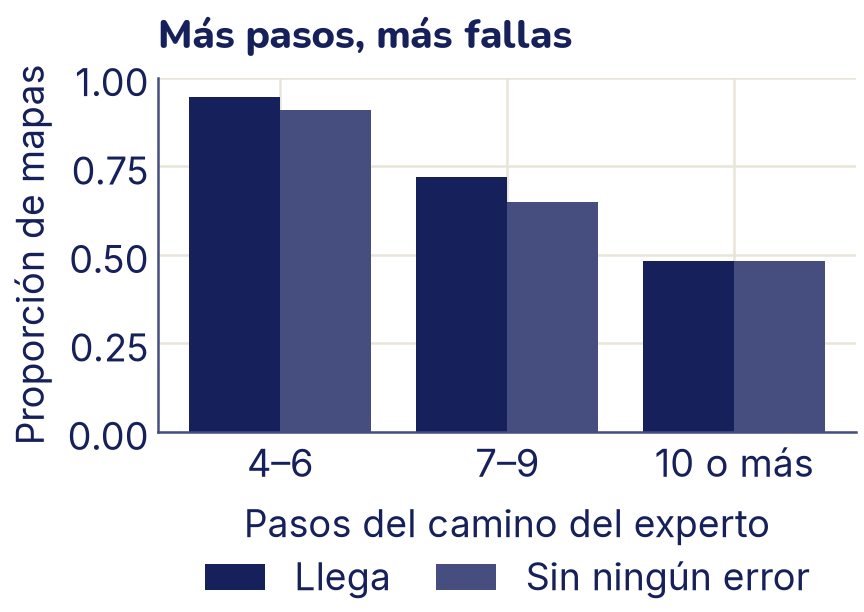

In [ ]:
grupos = [(4, 6), (7, 9), (10, 40)]
nombres, llegan, sin_error = [], [], []
for desde, hasta in grupos:
    en_grupo = (distancia >= desde) & (distancia <= hasta)
    nombres.append(f"{desde}–{hasta}" if hasta < 40 else f"{desde} o más")
    llegan.append(llego[en_grupo].mean())
    sin_error.append(perfecto[en_grupo].mean())
    print(f"{nombres[-1]} pasos ({en_grupo.sum()} mapas): llega "
          f"{llegan[-1]:.0%}, sin ningún error {sin_error[-1]:.0%}")

x = np.arange(len(grupos))
plt.bar(x - 0.2, llegan, width=0.4, color="C0", label="Llega")
plt.bar(x + 0.2, sin_error, width=0.4, color="C2", label="Sin ningún error")
plt.xticks(x, nombres)
plt.xlabel("Pasos del camino del experto")
plt.ylabel("Proporción de mapas")
plt.ylim(0, 1)
# Leyenda debajo del gráfico, para que no tape las barras del medio
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2,
           frameon=False, handlelength=1.6, columnspacing=1.2)
plt.title("Más pasos, más fallas")
plt.show()

Con caminos cortos, el robot casi nunca falla; con caminos de 10 pasos o más, llega en menos de la mitad de los mapas. Los números reales no siguen exactamente la cuenta de *p* elevado a *k*, porque los errores no son independientes: se concentran en los mapas difíciles. Pero la tendencia es la misma, y es lo que se llama **error compuesto** o que se acumula. La diferencia entre «Llega» y «Sin ningún error» también dice algo: a veces el robot se equivoca y aun así se recupera, sobre todo en caminos cortos.

Hay una segunda razón, más sutil. El experto **nunca se equivoca**, así que todas las demostraciones son situaciones sobre el camino más corto. Cuando la red se equivoca una vez, el robot queda en una casilla que el experto nunca visitó en ese mapa: una situación que no aparece en los datos de entrenamiento. Ahí la red adivina peor, y un error lleva a otro. Este es el problema central de la clonación de comportamiento: los datos de entrenamiento salen de la política del experto, pero la red se evalúa con **su propia** política, que la lleva a lugares distintos.

### La idea de DAgger

Una solución se llama **DAgger** (*Dataset Aggregation*, «juntar datos»). Funciona en rondas:

1. Entrena la red con las demostraciones del experto, como hicimos.
2. Deja que **la red** juegue en mapas nuevos y guarda todas las casillas que visitó, incluso las de sus errores.
3. Pregúntale al **experto** qué habría hecho en cada una de esas casillas. Ese es el truco: el experto etiqueta las situaciones a las que llega la red, no solo las suyas.
4. Junta esos ejemplos nuevos con los anteriores, vuelve a entrenar y repite desde el paso 2.

Ronda tras ronda, los datos de entrenamiento se parecen cada vez más a las situaciones que la red encuentra de verdad, incluidas las de recuperarse de un error. Nuestro experto es un programa y responde gratis; con un experto humano, cada pregunta cuesta tiempo, y por eso DAgger se usa con cuidado. En el mini-proyecto puedes probar una ronda.

### La medición final

Con todas las decisiones tomadas, medimos una sola vez con los mapas ocultos:

In [ ]:
llego_oculto = np.array([jugar(imitador, m, i)[0]
                         for m, i, d in mapas_ocultos])
print(f"Llega a la meta en {llego_oculto.mean():.1%} de los mapas ocultos")

Llega a la meta en 78.0% de los mapas ocultos


En los mapas ocultos llega el 78,0 % de las veces, casi lo mismo que en los públicos (77,3 %). Es una buena noticia: como no usamos los mapas públicos para entrenar ni para ajustar nada fino, su cifra ya era honesta. Si hubiéramos probado cien arquitecturas y elegido la mejor mirando los mapas públicos, la cifra pública se habría inflado un poco, y la oculta nos lo habría dicho.

## Refuerzo o imitación

| | Aprendizaje por refuerzo | Clonación de comportamiento |
|---|---|---|
| Qué necesita | Un entorno donde probar y una recompensa | Demostraciones de un experto |
| Cómo aprende | Prueba y error, con muchos episodios | Clasificación supervisada |
| Puede superar al experto | Sí: busca lo que da más recompensa | No: a lo sumo lo copia |
| Riesgo principal | Tarda mucho; una recompensa mal pensada enseña otra cosa | Los errores se acumulan en situaciones nuevas |

En la práctica se combinan: primero se imita a un experto para empezar con algo razonable y después se mejora con refuerzo. Una advertencia sobre la recompensa: el agente optimiza exactamente lo que se le premia, no lo que uno quería decir. Un agente premiado por «sumar puntos» en un juego puede descubrir una manera de sumar puntos girando en círculos sin terminar nunca la carrera. Pensar bien la recompensa es la mitad del trabajo.

## Lo que aprendiste y lo que sigue

- En el **aprendizaje por refuerzo**, un **agente** elige **acciones** en un **entorno**, pasa de **estado** en estado y recibe **recompensas**. Una partida es un **episodio** y la regla para elegir es la **política**.
- El **retorno** suma las recompensas multiplicando cada una por γ una vez por paso de espera: el **descuento** le da prisa al agente.
- La **iteración de valor** aplica la ecuación de Bellman a todas las casillas hasta que los valores dejan de cambiar. Es exacta, pero necesita conocer el mapa.
- El **Q-learning** aprende jugando: después de cada paso corrige *Q*(*s*, *a*) con una parte α de la sorpresa. Con **ε-greedy** mezcla explorar y explotar.
- La **clonación de comportamiento** convierte la imitación en clasificación supervisada: una CNN aprendió a predecir la acción de un experto a partir del mapa como tensor (3, 8, 8).
- En la imitación los errores **se acumulan**: la red llega a situaciones que el experto nunca mostró. **DAgger** le pide al experto que etiquete justamente esas situaciones.

La ruta sigue en el tema 21, con otro tipo de datos: el **texto**.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `MAPA`, `FLECHAS`, `paso`, `iteracion_de_valor`, `politica_desde_v`, `politica_optima`, `q_learning`, `codificar`, `mapas_publicos` e `imitador`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio con lápiz y papel antes de abrir la respuesta.

## Ejercicios

### 1. El retorno a mano

Un robot puede elegir entre dos caminos. El camino A llega en 6 pasos a una meta que da +1. El camino B llega en 3 pasos a una «meta chica» que da +0,5. Las demás recompensas son 0.

a) Con γ = 0,9, ¿cuánto vale el retorno de cada camino? ¿Cuál prefiere el robot?

b) ¿Y con γ = 0,5?

c) Comprueba las cuentas con código.

<details>
<summary>Respuesta</summary>

La recompensa llega en el último paso, así que se multiplica por γ una vez por cada paso de espera: *k* − 1 veces.

a) Con γ = 0,9: el camino A vale 0,9⁵ · 1 = 0,59049 y el B vale 0,9² · 0,5 = 0,81 · 0,5 = 0,405. Prefiere el **A**: la meta grande compensa la espera.

b) Con γ = 0,5: el A vale 0,5⁵ = 0,03125 y el B vale 0,5² · 0,5 = 0,125. Ahora prefiere el **B**. Con un descuento fuerte, el robot es impaciente: un premio chico pronto le gana a uno grande tarde.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for gamma in [0.9, 0.5]:
    camino_a = gamma ** 5 * 1
    camino_b = gamma ** 2 * 0.5
    print(f"γ = {gamma}: A = {camino_a:.5f}, B = {camino_b:.5f}")

### 2. Una corrección de Q-learning a mano

El robot está en la casilla *s* y cree que la acción *a* vale *Q*(*s*, *a*) = 0,2. Da el paso, recibe *r* = 0 y llega a *s*′, donde el mejor de sus cuatro *Q* vale 0,5. Usa α = 0,5 y γ = 0,9.

a) ¿Cuál es el objetivo *r* + γ · máx *Q*(*s*′, ·)? ¿Cuál es la sorpresa? ¿Cuánto vale *Q*(*s*, *a*) después de la corrección?

b) Ahora imagina que, desde la misma casilla con el mismo *Q*(*s*, *a*) = 0,2, el paso cae en una trampa: *r* = −1 y el episodio termina. ¿Cuánto vale *Q*(*s*, *a*) después?

<details>
<summary>Respuesta</summary>

a) El objetivo es 0 + 0,9 · 0,5 = 0,45. La sorpresa es 0,45 − 0,2 = 0,25: la acción era mejor de lo que creía. Con α = 0,5 se corrige la mitad: 0,2 + 0,5 · 0,25 = **0,325**.

b) El episodio terminó, así que no hay futuro: el objetivo es solo *r* = −1. La sorpresa es −1 − 0,2 = −1,2, y el nuevo valor es 0,2 + 0,5 · (−1,2) = **−0,4**. Una sola caída basta para que esa acción quede por debajo de las otras.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
alfa, gamma, q = 0.5, 0.9, 0.2
objetivo = 0 + gamma * 0.5
print(round(q + alfa * (objetivo - q), 3))
objetivo = -1                     # trampa: sin futuro
print(round(q + alfa * (objetivo - q), 3))

### 3. ¿Qué pasa con γ = 0,5 y con γ = 1?

Corre la iteración de valor sobre `MAPA` con γ = 0,5 y con γ = 1. Para cada uno, mira el valor del inicio, la acción que elige la política en el inicio y en cuántas de las 40 casillas libres coincide con `politica_optima` (la de γ = 0,9). Antes de correrlo, predice: ¿cambia el camino con γ = 0,5? ¿Y con γ = 1?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
libres = ~np.isin(MAPA, ["#", "M", "T"])
for g in [0.5, 1.0]:
    V_g, vueltas_g = iteracion_de_valor(MAPA, gamma=g)
    pol_g = politica_desde_v(MAPA, V_g, gamma=g)
    iguales = (pol_g == politica_optima)[libres].sum()
    print(f"γ = {g}: {vueltas_g} vueltas, V del inicio {V_g[0, 0]:.6f}")
    print(f"   acción en el inicio {FLECHAS[pol_g[0, 0]]}, "
          f"coincide en {iguales} de 40")

<details>
<summary>Respuesta</summary>

Con γ = 0,5 el valor del inicio es diminuto, 0,5¹³ ≈ 0,000122, pero la política es **la misma** en las 40 casillas. En este mapa solo hay recompensa al final y el entorno es determinista: para cualquier γ entre 0 y 1, el mejor plan es el camino más corto, y γ solo cambia cuánto valen las casillas, no el orden entre ellas.

Con γ = 1 todo se rompe. Llegar en 14 pasos o en 1000 da lo mismo, así que toda casilla desde la que se puede llegar vale 1, igual que el inicio. Hasta **quedarse quieto** vale 1: chocar contra el borde deja al robot en una casilla de valor 1. Las cuatro acciones empatan, `argmax` elige la primera, ↑, y el robot choca contra el borde para siempre. Solo coincide con la política óptima en 9 casillas. Sin descuento (y sin costo por paso), el robot no tiene ninguna prisa.

</details>

### 4. La tasa de aprendizaje α

Entrena el Q-learning de la teoría con α = 0,05, 0,5 y 1, con todo lo demás igual. Compara la recompensa media de los primeros y de los últimos 100 episodios y el *Q* del inicio con el valor exacto, 0,254. ¿Cuál aprende más rápido? ¿Por qué α = 1 no causa problemas en este entorno?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for alfa in [0.05, 0.5, 1.0]:
    Q_a, rec = q_learning(MAPA, alfa=alfa)
    print(f"α = {alfa}: primeros 100 {rec[:100].mean():.2f}, "
          f"últimos 100 {rec[-100:].mean():.2f}, "
          f"Q del inicio {Q_a[0, 0].max():.3f}")

<details>
<summary>Respuesta</summary>

Sorpresa: las recompensas son las mismas con los tres α. El robot elige sus acciones por **cuál** *Q* es el más alto, no por cuánto vale exactamente, y en este mapa ese orden se decide igual con cualquier α: una trampa deja la acción en negativo, una meta la deja en positivo. Donde sí se nota α es en los números. Con α = 0,05, el *Q* del inicio va en 0,225, todavía lejos del valor exacto 0,254: cada experiencia lo mueve solo un 5 % de la sorpresa. Con α = 0,5 y con α = 1 ya llegó.

α = 1 no causa problemas porque el entorno es **determinista**: la misma acción da siempre el mismo resultado, así que reemplazar la estimación entera por lo último que se vio no pierde nada. Si el robot resbalara a veces, cada experiencia diría algo distinto y con α = 1 la tabla saltaría de un valor a otro sin asentarse; ahí conviene un α chico, que promedia muchas experiencias.

</details>

### 5. Encuentra el error

Alguien quiere probar el imitador con una sola situación y escribe esto:

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
mapa, inicio, dist = mapas_publicos[0]
x = torch.tensor(codificar(mapa, inicio))
x = x.permute(1, 2, 0).unsqueeze(0)
print(tuple(x.shape))
print(imitador(x))

(1, 8, 8, 3)
Traceback (most recent call last):
  ...
RuntimeError: Given groups=1, weight of size [32, 3, 3, 3], expected input[1, 8, 8, 3] to have 3 channels, but got 8 channels instead


¿Qué está mal y cómo se arregla?

<details>
<summary>Respuesta</summary>

`permute(1, 2, 0)` movió los canales al final: el tensor quedó como (1, 8, 8, 3), la forma de una imagen de matplotlib. `nn.Conv2d` espera (N, C, H, W), así que leyó 8 canales donde esperaba 3. `codificar` ya devuelve (3, 8, 8); basta con agregar el eje del lote:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
x = torch.tensor(codificar(mapa, inicio)).unsqueeze(0)
print(tuple(x.shape))
with torch.no_grad():
    print(FLECHAS[imitador(x).argmax().item()])

### 6. El error compuesto en números

Una red imitadora da un paso bueno con probabilidad *p*, y supón que los pasos son independientes.

a) Con *p* = 0,95, ¿qué probabilidad tiene de completar sin errores un camino de 10 pasos? ¿Y uno de 20?

b) ¿Qué *p* hace falta para completar sin errores un camino de 20 pasos el 90 % de las veces?

<details>
<summary>Respuesta</summary>

a) 0,95¹⁰ ≈ 0,599 y 0,95²⁰ ≈ 0,358. Con caminos el doble de largos, la probabilidad casi se reduce a la mitad, aunque la red sea igual de buena en cada paso.

b) Hace falta *p*²⁰ = 0,9, o sea, *p* = 0,9 elevado a 1/20 (la raíz vigésima de 0,9), que es más o menos 0,9947: menos de un error cada 190 pasos. Por eso la imitación pura es tan exigente en tareas largas, como manejar.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print(round(0.95 ** 10, 3), round(0.95 ** 20, 3))
p_necesaria = 0.9 ** (1 / 20)
print(round(p_necesaria, 4), round(1 / (1 - p_necesaria)))

### 7. ¿Refuerzo, imitación o supervisado?

Para cada situación, di qué tipo de aprendizaje usarías y por qué.

a) Un programa aprende a jugar ajedrez jugando millones de partidas contra sí mismo; solo sabe al final si ganó, perdió o empató.

b) Un auto aprende a mantenerse en su carril a partir de horas de video grabado mientras manejaban personas, con el ángulo del volante en cada momento.

c) Un modelo aprende a reconocer prendas en fotos etiquetadas.

d) Imagina un robot de limpieza al que se premia cada vez que su cámara **no ve** suciedad. ¿Qué podría «aprender» que nadie quería?

<details>
<summary>Respuesta</summary>

a) **Refuerzo.** No hay un experto que diga la jugada correcta en cada posición; solo una recompensa al final (ganar, perder, empatar), que llega tarde.

b) **Imitación** (clonación de comportamiento): hay demostraciones de expertos, cada situación con la acción que tomaron. Ojo con el error compuesto: el video solo muestra al auto bien centrado, nunca cómo corregir cuando se desvía, que es justo el problema que DAgger ataca.

c) **Supervisado**, como en los temas 18 a 20: cada foto tiene su respuesta y no hay acciones ni pasos.

d) Podría aprender a mirar a la pared, a taparse la cámara o a quedarse quieto en un rincón limpio: así su cámara nunca ve suciedad y recibe el premio sin limpiar nada. El agente optimiza lo que se premia, no lo que se quería. Una recompensa mejor premiaría la suciedad recogida.

</details>

## Mini-proyecto: un robot que mejora con DAgger

Vas a aplicar una ronda de DAgger al imitador de la teoría y a medir si ayuda.

1. **La línea de base.** Anota la tasa de llegada del imitador de la teoría en los mapas públicos y, por grupos de largo, la tasa sin ningún error.
2. **Mapas nuevos para la ronda.** Genera 1000 mapas nuevos con `mapa_al_azar` y otra semilla (por ejemplo, `np.random.default_rng(7)`). No uses los mapas públicos ni los ocultos para esto: son para medir.
3. **Que juegue la red.** Escribe una versión de `jugar` que, además del recorrido, guarde cada situación que visitó la red con `codificar(mapa, s)`. Juega en los 1000 mapas.
4. **Que etiquete el experto.** Para cada situación visitada, pide al experto su acción con `experto(dist, s)`. Ojo: si la red se quedó chocando contra una pared, la misma casilla aparece muchas veces; puedes guardarla una sola vez.
5. **Juntar y reentrenar.** Une los ejemplos nuevos con `X_ent` y `y_ent` (con `np.concatenate`), arma un cargador nuevo y entrena una red igual a `imitador` desde cero, con la misma semilla y las mismas 10 épocas.
6. **Compara en los mapas públicos.** ¿Subió la tasa de llegada? ¿En qué grupo de largo mejoró más? Repite los pasos 3 a 5 una segunda ronda si tienes tiempo, y haz una tabla con las rondas.
7. **Mide al final.** Con la mejor versión, elegida solo con los mapas públicos, mide **una sola vez** en mapas ocultos. Los de la teoría ya se usaron una vez para medir el imitador original: genera 300 mapas ocultos nuevos con otra semilla, guárdalos sin mirarlos y mide ahí.
8. **Concluye.** Escribe tres conclusiones de una o dos frases: ¿cuánto ayudó DAgger? ¿Qué tipo de mapas siguen siendo difíciles? ¿Cuántas preguntas le hiciste al experto, y cuánto costaría eso si el experto fuera una persona?

Si quieres ir más lejos con el refuerzo: agrega a `paso` una recompensa de −0,01 en cada paso normal y repite el Q-learning de la teoría con ε = 0. ¿Qué cambia? Pista: con un costo por paso, las acciones ya probadas quedan por debajo de 0 y las que nunca se probaron, en 0, parecen mejores. El robot explora aunque ε sea 0.

## Errores comunes

- **Olvidar que el episodio terminó.** Si el paso cae en la meta o en una trampa, el objetivo es solo *r*: no hay casilla siguiente de la que sumar γ · máx *Q*.
- **Evaluar con ε.** La recompensa durante el entrenamiento incluye los pasos al azar. Para saber qué aprendió el robot, sigue sus flechas sin exploración, como hicimos con `llega_desde`.
- **ε = 0 desde el principio.** Sin exploración, el robot repite el primer camino que encontró y no sabe nada del resto del mapa.
- **γ = 1 en un problema sin costo por paso.** Llegar en 14 pasos o en 1000 da lo mismo, y quedarse quieto vale tanto como avanzar (ejercicio 3).
- **Creerle a la recompensa media del final.** Una curva de recompensa salta mucho de episodio a episodio: mira la media móvil y prueba con varias semillas antes de concluir.
- **Repartir los pasos, no los mapas.** Si los pasos de un mismo mapa quedan unos en entrenamiento y otros en validación, la red se evalúa con mapas que ya vio y la cifra sale inflada.
- **Medir la imitación solo con la exactitud por paso.** Lo que importa es si el robot completa la tarea, y los errores se acumulan con el largo del camino.
- **Decidir mirando los mapas ocultos.** Se usan una sola vez, al final. Si los miras para elegir, ya no miden nada nuevo.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Describir un problema como agente, estados, acciones, recompensa y episodio, y explicar el factor de descuento γ (ejercicios 1 y 7, y el paso 6 de la actividad).
- Programar la iteración de valor y el Q-learning con ε-greedy, y leer la política resultante como flechas (ejercicios 2 y 3, y pasos 1 y 2 de la actividad).
- Explicar el dilema entre explorar y explotar y el efecto de α, γ y ε (ejercicios 3 y 4, y pasos 3 a 5 de la actividad).
- Enseñar a un robot imitando a un experto, con el mapa como tensor (3, 8, 8), y medir su tasa de llegada en mapas nuevos (ejercicio 5 y pasos 1, 5 y 7 del mini-proyecto).
- Reconocer el error que se acumula en la imitación y explicar la idea de DAgger (ejercicios 6 y 7, y pasos 3 a 6 del mini-proyecto).